# Project 4: Document Classification of Math Problems by Subject
**Joao De Oliveira** · DATA 620

## Assignment
Use documents that are already labeled to predict the class of new documents. Instead of the spambase data, I use a set of math problems that are already tagged by subject. I train classifiers on most of the problems, then predict the subject of problems the classifier has never seen. Since I teach math and design curriculum, this is a task I really care about: a classifier like this could tag a large bank of practice problems automatically.

## 1. The data
The **MATH dataset** (Hendrycks et al., 2021) has 12500 problems from U.S. math competitions such as the AMC 10, AMC 12 and AIME. Each problem is labeled with one of 7 subjects: Prealgebra, Algebra, Intermediate Algebra, Number Theory, Counting & Probability, Geometry and Precalculus. The problems are raw text, with the math written in LaTeX (for example `$\frac{1}{2}$`).

I download the copy in openAI's `prm800k` github repository. It is split into 12000 + 500 problems, and I combine both files and make my own split below.

In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

SEED = 42
BASE_URL = 'https://media.githubusercontent.com/media/openai/prm800k/main/prm800k/math_splits/'

# use local, otherwise download from GitHub
parts = []
for split in ['train', 'test']:
    local = f'data/{split}.jsonl'
    source = local if os.path.exists(local) else BASE_URL + f'{split}.jsonl'
    parts.append(pd.read_json(source, lines=True))
math_df = pd.concat(parts, ignore_index=True)

print('Problems:', len(math_df))
print('Columns:', list(math_df.columns))
math_df[['problem', 'subject', 'level']].head()

Problems: 12500
Columns: ['problem', 'solution', 'answer', 'subject', 'level', 'unique_id']


,problem,subject,level
0,How many vertical asymptotes does the graph of...,Algebra,3
1,"If $5x - 3 = 12$, what is the value of $5x + 3$?",Prealgebra,2
2,Ryan has 3 red lava lamps and 3 blue lava lamp...,Counting & Probability,5
3,Alice wants to buy $3$ pounds of veal at the g...,Prealgebra,4
4,"On the $xy$-plane, the origin is labeled with ...",Counting & Probability,5


Each row also has a worked solution and the final answer. I only use the problem text, because a new problem wouldn't come with its solution.

In [2]:
n_dup = math_df['problem'].duplicated().sum()
math_df = math_df.drop_duplicates('problem').reset_index(drop=True)
print(f'Duplicate problems removed: {n_dup}  ->  {len(math_df)} problems\n')

counts = math_df['subject'].value_counts()
print(pd.DataFrame({'problems': counts, 'percent': (counts / len(math_df) * 100).round(1)}))
print(f"\nMedian problem length: {math_df['problem'].str.len().median():.0f} characters")

Duplicate problems removed: 1  ->  12499 problems

                        problems  percent
subject                                  
Algebra                     2931     23.4
Intermediate Algebra        2198     17.6
Prealgebra                  2076     16.6
Number Theory               1409     11.3
Geometry                    1349     10.8
Precalculus                 1291     10.3
Counting & Probability      1245     10.0

Median problem length: 146 characters


The subjects are not balanced. Algebra is the largest class (23.4%), so a classifier that always guesses "Algebra" would be right 23.4% of the time. That is the baseline to beat.

## 2. Hold back the "new" problems
I split the data 80/20, stratified by subject. The 20% test set is not used until section 6.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    math_df['problem'], math_df['subject'],
    test_size=0.20, stratify=math_df['subject'], random_state=SEED)

print(f'Training set: {len(X_train)} problems')
print(f'Test set:     {len(X_test)} problems')

Training set: 9999 problems
Test set:     2500 problems


## 3. Turning problems into features
A classifier needs numbers, so each problem becomes a vector of token weights (TF-IDF: a token gets a high weight when it is frequent in this problem but rare across all problems).

The tokenizer matters a lot here. scikit-learn's default tokenizer keeps only words with more than 2 letters or digits, so it throws away most of the math: `\frac` becomes `frac`, and single-letter symbols and operators like `x`, `^`, `=` and `!` are dropped. I wrote a **math-aware tokenizer** that keeps LaTeX commands (`\sin`, `\binom`, `\pmod`), single letters, numbers and symbols as tokens.

In [4]:
DEFAULT_PATTERN = r'(?u)\b\w\w+\b'
MATH_PATTERN = r'\\[A-Za-z]+|[A-Za-z]+|\d+|[^\sA-Za-z\d]'

example = r'Compute $\binom{8}{3}$. What is $\sin^2 x + \cos^2 x$ if $x! = 6$?'
print('Problem:  ', example)
print('Default:  ', re.findall(DEFAULT_PATTERN, example.lower()))
print('Math-aware:', re.findall(MATH_PATTERN, example))

Problem:   Compute $\binom{8}{3}$. What is $\sin^2 x + \cos^2 x$ if $x! = 6$?
Default:   ['compute', 'binom', 'what', 'is', 'sin', 'cos', 'if']
Math-aware: ['Compute', '$', '\\binom', '{', '8', '}', '{', '3', '}', '$', '.', 'What', 'is', '$', '\\sin', '^', '2', 'x', '+', '\\cos', '^', '2', 'x', '$', 'if', '$', 'x', '!', '=', '6', '$', '?']


## 4. Which features work best?
I compare three feature sets with the same classifier (a linear support vector machine), using 5 fold cross validation on the training set only:
1. **Words:** default tokenizer
2. **Words + math:** math-aware tokenizer
3. **Words + math, with word pairs:** math-aware tokenizer, single tokens plus pairs of neighboring tokens (bigrams, such as `\frac {` or `how many`). Any token or pair that appears in only one training problem is dropped.

In [5]:
feature_sets = {
    'Words': dict(token_pattern=DEFAULT_PATTERN),
    'Words + math': dict(token_pattern=MATH_PATTERN, lowercase=False),
    'Words + math, with word pairs': dict(token_pattern=MATH_PATTERN, lowercase=False,
                                          ngram_range=(1, 2), min_df=2),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for name, params in feature_sets.items():
    pipe = make_pipeline(TfidfVectorizer(sublinear_tf=True, **params), LinearSVC())
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, n_jobs=-1)
    n_features = TfidfVectorizer(**params).fit(X_train).vocabulary_.__len__()
    rows.append({'features': name, 'vocabulary size': n_features, 'CV accuracy': scores.mean()})

feat_results = pd.DataFrame(rows)
feat_results.style.format({'CV accuracy': '{:.1%}', 'vocabulary size': '{:,}'}).hide(axis='index')

features,vocabulary size,CV accuracy
Words,"9,275",73.7%
Words + math,"8,803",76.5%
"Words + math, with word pairs","29,686",79.4%


## 5. Which classifier works best?
Using the best feature set, I compare the three classifier types from the NLTK book, plus a linear support vector machine, a standard choice for text:
- **Naive Bayes** (multinomial, on raw token counts)
- **Logistic regression** (the book's maximum entropy model)
- **Decision tree**
- **Linear SVM**

In [6]:
best_features = feat_results.loc[feat_results['CV accuracy'].idxmax(), 'features']
params = feature_sets[best_features]
print('Feature set:', best_features, '\n')

models = {
    'Naive Bayes': make_pipeline(CountVectorizer(**params), MultinomialNB()),
    'Logistic regression': make_pipeline(TfidfVectorizer(sublinear_tf=True, **params),
                                         LogisticRegression(max_iter=3000)),
    'Decision tree': make_pipeline(TfidfVectorizer(sublinear_tf=True, **params),
                                   DecisionTreeClassifier(random_state=SEED)),
    'Linear SVM': make_pipeline(TfidfVectorizer(sublinear_tf=True, **params), LinearSVC()),
}

rows = []
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, n_jobs=-1)
    rows.append({'model': name, 'CV accuracy': scores.mean(), 'std': scores.std()})

cv_results = pd.DataFrame(rows).sort_values('CV accuracy', ascending=False).reset_index(drop=True)
print(f"Baseline (always guess Algebra): {(y_train == 'Algebra').mean():.1%}")
cv_results.style.format({'CV accuracy': '{:.1%}', 'std': '{:.1%}'})

Feature set: Words + math, with word pairs 

Baseline (always guess Algebra): 23.5%


,model,CV accuracy,std
0,Linear SVM,79.4%,0.7%
1,Logistic regression,76.9%,0.7%
2,Naive Bayes,66.4%,1.0%
3,Decision tree,64.7%,0.7%


In [7]:
best_name = cv_results.loc[0, 'model']
best_cv = cv_results.loc[0, 'CV accuracy']
print(f'Best model in cross-validation: {best_name} ({best_cv:.1%})')

Best model in cross-validation: Linear SVM (79.4%)


## 6. Predict the held-out problems
I retrain the best model on the full training set and classify the 2500 test problems. This is the only time the test set is used.

In [8]:
final_model = models[best_name].fit(X_train, y_train)
y_pred = final_model.predict(X_test)
test_acc = accuracy_score(y_test, y_pred)

print(f'{best_name}')
print(f'  Cross-validation accuracy (training): {best_cv:.1%}')
print(f'  Test accuracy (new problems):         {test_acc:.1%}\n')
print(classification_report(y_test, y_pred, digits=3))

Linear SVM
  Cross-validation accuracy (training): 79.4%
  Test accuracy (new problems):         78.7%

                        precision    recall  f1-score   support

               Algebra      0.777     0.833     0.804       586
Counting & Probability      0.745     0.799     0.771       249
              Geometry      0.783     0.841     0.811       270
  Intermediate Algebra      0.895     0.832     0.862       440
         Number Theory      0.801     0.787     0.794       282
            Prealgebra      0.616     0.588     0.602       415
           Precalculus      0.953     0.860     0.904       258

              accuracy                          0.787      2500
             macro avg      0.796     0.791     0.793      2500
          weighted avg      0.789     0.787     0.787      2500



### Which subjects get mixed up?
Each row of the confusion matrix is the true subject, and each column is the predicted one. The numbers are the percentage of each true subject's problems that got each label, so every row adds up to 100%.

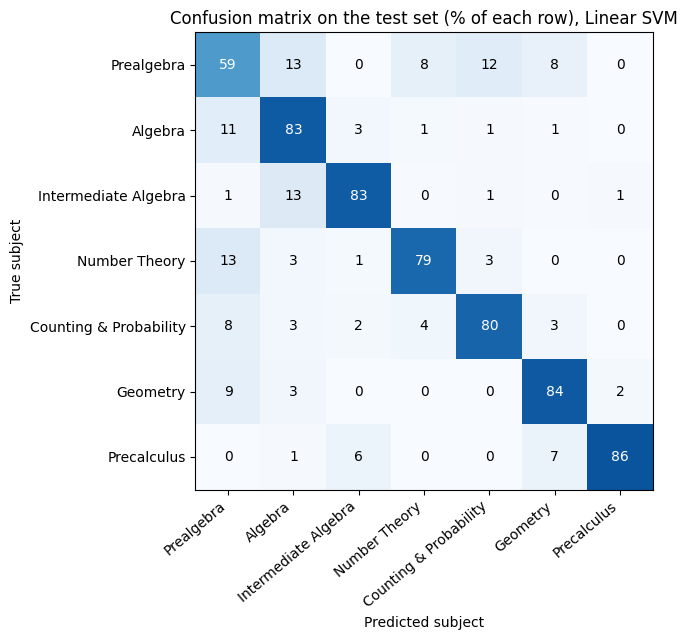

In [9]:
subjects = ['Prealgebra', 'Algebra', 'Intermediate Algebra', 'Number Theory',
            'Counting & Probability', 'Geometry', 'Precalculus']
cm = confusion_matrix(y_test, y_pred, labels=subjects)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.imshow(cm_pct, cmap='Blues', vmin=0, vmax=100)
ax.set_xticks(range(7))
ax.set_xticklabels(subjects, rotation=40, ha='right')
ax.set_yticks(range(7))
ax.set_yticklabels(subjects)
for i in range(7):
    for j in range(7):
        ax.text(j, i, f'{cm_pct[i, j]:.0f}', ha='center', va='center',
                color='white' if cm_pct[i, j] > 50 else 'black')
ax.set_xlabel('Predicted subject')
ax.set_ylabel('True subject')
ax.set_title(f'Confusion matrix on the test set (% of each row), {best_name}')
plt.tight_layout()
plt.show()

In [10]:
# the most common mixups (true -> predicted), as counts
pairs = [(subjects[i], subjects[j], cm[i, j]) for i in range(7) for j in range(7) if i != j]
mixups = pd.DataFrame(pairs, columns=['true subject', 'predicted as', 'problems'])
mixups = mixups.sort_values('problems', ascending=False).head(6).reset_index(drop=True)
print(f'Total errors: {(y_test != y_pred).sum()} of {len(y_test)}')
mixups

Total errors: 532 of 2500


,true subject,predicted as,problems
0,Algebra,Prealgebra,63
1,Intermediate Algebra,Algebra,57
2,Prealgebra,Algebra,56
3,Prealgebra,Counting & Probability,48
4,Number Theory,Prealgebra,38
5,Prealgebra,Number Theory,35


## 7. What the model learned
For a linear model, each subject has a weight for every token. The table shows the 8 tokens with the largest weights for each subject, which are the clues the model relies on most.

In [11]:
vec = final_model[0]
clf = final_model[-1]
vocab = np.array(vec.get_feature_names_out())

top_tokens = {}
for k, subject in enumerate(clf.classes_):
    top = np.argsort(clf.coef_[k])[::-1][:8]
    top_tokens[subject] = ',  '.join(vocab[top])

pd.set_option('display.max_colwidth', None)
pd.DataFrame.from_dict(top_tokens, orient='index', columns=['strongest tokens']).loc[subjects]

,strongest tokens
Prealgebra,"average, mean, + (, ?, \div, $ \sqrt, and 12, Simplify"
Algebra,"$ ., arithmetic sequence, if }, equation $, geometric, } }, : \, ^"
Intermediate Algebra,". $, ellipse, , $, \dotsm, \log, hyperbola, polynomial, \times \frac"
Number Theory,"base, _, \pmod, modulo, \pmod {, in base, divisors, factors"
Counting & Probability,"probability, probability that, !, the probability, ways, expected, \dbinom, \dbinom {"
Geometry,"pyramid, $ ., a triangle, volume, radius, cylindrical, the volume, \triangle"
Precalculus,"\sin, \cos, \tan, \pi, . $, ABC ,, \cot, \arctan"


## 8. Classifying brand new problems
Finally, I wrote eight new problems in the style of my own classes, so they are not from the dataset at all. I added the subject I would give each one, then had the model classify them.

In [12]:
new_problems = pd.DataFrame([
    ('A shirt costs $\\$24$ and is on sale for $25\\%$ off. What is the sale price?', 'Prealgebra'),
    ('Solve for $x$: $3(x - 4) = 2x + 7$.', 'Algebra'),
    ('Find all real roots of $x^4 - 5x^2 + 4 = 0$.', 'Intermediate Algebra'),
    ('What is the remainder when $7^{100}$ is divided by $5$?', 'Number Theory'),
    ('A bag has 4 red and 6 blue marbles. Two are drawn without replacement. What is the probability both are red?', 'Counting & Probability'),
    ('A right triangle has legs of length 6 and 8. What is the radius of its inscribed circle?', 'Geometry'),
    ('Find $\\cos \\theta$ if $\\sin \\theta = \\frac{3}{5}$ and $\\theta$ is in the second quadrant.', 'Precalculus'),
    ('How many positive divisors does $360$ have?', 'Number Theory'),
], columns=['problem', 'my label'])

new_problems['predicted'] = final_model.predict(new_problems['problem'])
new_problems['correct'] = new_problems['my label'] == new_problems['predicted']
print(f"Correct: {new_problems['correct'].sum()} of {len(new_problems)}")
new_problems

Correct: 5 of 8


,problem,my label,predicted,correct
0,A shirt costs $\$24$ and is on sale for $25\%$ off. What is the sale price?,Prealgebra,Algebra,False
1,Solve for $x$: $3(x - 4) = 2x + 7$.,Algebra,Prealgebra,False
2,Find all real roots of $x^4 - 5x^2 + 4 = 0$.,Intermediate Algebra,Intermediate Algebra,True
3,What is the remainder when $7^{100}$ is divided by $5$?,Number Theory,Number Theory,True
4,A bag has 4 red and 6 blue marbles. Two are drawn without replacement. What is the probability both are red?,Counting & Probability,Counting & Probability,True
5,A right triangle has legs of length 6 and 8. What is the radius of its inscribed circle?,Geometry,Geometry,True
6,Find $\cos \theta$ if $\sin \theta = \frac{3}{5}$ and $\theta$ is in the second quadrant.,Precalculus,Precalculus,True
7,How many positive divisors does $360$ have?,Number Theory,Prealgebra,False


## 9. Conclusions

**Data.** The MATH dataset has 12499 unique competition problems (after removing 1 duplicate), each tagged with one of 7 subjects. I held back 2500 (20%) as the "new" problems and trained on the other 9999. Unlike Spambase, these are raw text, so I had to build the features myself.

**Features mattered as much as the classifier.** With the default tokenizer, which throws away most of the math notation, the linear SVM reached 73.7% in cross-validation. Keeping Latex commands, single letters, numbers and symbols raised it to 76.5%, and adding neighboring token pairs raised it to 79.4%. In math problems, the notation (`\sin`, `\pmod`, `\binom`, `!`) carries a lot of the meaning.

**Choosing a classifier.** The linear SVM did best in cross-validation (79.4%), ahead of logistic regression (76.9%), naive Bayes (66.4%) and the decision tree (64.7%). All four beat the 23.5% baseline of always guessing Algebra. The decision tree does worst because it can only split on a few tokens at a time, while a subject is signaled by many small clues together.

**Predicting the new problems.** On the 2,500 held-out problems, the model scores **78.7%**, close to its cross-validation estimate (79.4%). That is what I expected: the test set wasn't used for any decisions, so its score is an honest estimate.

**Where it goes wrong.** Precalculus (86.0% of its problems found), Geometry (84.1%) and the two algebra subjects (about 83%) are recognized best. Prealgebra is much harder (58.8%): its problems get spread over Algebra (13%), Counting & Probability (12%), Number Theory (8%) and Geometry (8%). This makes sense to me as a teacher. Prealgebra covers the basics of every other subject, so what separates it is mostly difficulty, not vocabulary. The other big mix-ups are also between neighboring levels: Algebra predicted as Prealgebra (63 problems) and Intermediate Algebra predicted as Algebra (57).

**What it learned.** The strongest tokens make sense: `\sin`, `\cos` and `\tan` for Precalculus, `\pmod`, "modulo" and "base" for Number Theory, "probability", "ways" and `!` for Counting & Probability, and "volume", "radius" and `\triangle` for Geometry. A few tokens, like `$ .`, describe how the dataset's authors format their LaTeX rather than the math itself. Like "george" in Spambase, these would not carry over to problems written by someone else.

**My own problems.** The model got 5 of my 8 new problems right. All 3 misses involve prealgebra (a sale price problem and a linear equation went to the wrong side of the prealgebra/Algebra line, and a divisor-counting problem was called prealgebra instead of Number Theory). That is the same weakness the test set showed. Honestly, some of these could go either way, which shows how fuzzy the line between levels is.